<!-- Checkpoint 4 (CP04) — Task 4.3: Dev feature distributions (POS, NEG, INT) and correlations -->
# Checkpoint 4 — Task 4.3: Dev Feature Distributions & Correlations

In [7]:
# Checkpoint 4 (CP04) — Task 4.3: Dev feature distributions (POS, NEG, INT) and correlations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "data/processed").exists():
    for parent in root.parents:
        if (parent / "data/processed").exists():
            root = parent
            break

dev_df = pd.read_parquet(root / "data/processed/sst_dev_features.parquet")
print("Resolved repo root:", root)
print("Shape:", dev_df.shape)
print("Columns:", list(dev_df.columns))
dev_df[["POS", "NEG", "INT", "clue_a", "clue_b", "clue_c", "clue_d"]].describe().round(4)

Resolved repo root: c:\Internship
Shape: (1101, 21)
Columns: ['sentence_index', 'sentence', 'splitset_label', 'phrase', 'phrase_id', 'score', 'label_3class', 'label_5class', 'p_neg', 'p_neu', 'p_pos', 'vpos', 'vneg', 'compound', 'POS', 'NEG', 'clue_a', 'clue_b', 'clue_c', 'clue_d', 'INT']


,POS,NEG,INT,clue_a,clue_b,clue_c,clue_d
count,1101.0000,1101.0000,1101.0000,1101.0000,1101.0000,1101.0000,1101.0000
mean,0.3121,0.3073,0.1166,0.0406,0.0030,0.0013,0.4215
std,0.3090,0.2901,0.0785,0.1294,0.0316,0.0103,0.2774
min,0.0030,0.0013,0.0000,0.0000,0.0000,0.0000,0.0000
25%,0.0497,0.0216,0.0621,0.0000,0.0000,0.0000,0.2200
50%,0.1589,0.2108,0.1147,0.0000,0.0000,0.0000,0.4340
75%,0.5998,0.5862,0.1740,0.0000,0.0000,0.0000,0.6486
max,0.9892,0.9675,0.4174,1.0000,0.3333,0.2000,0.9688


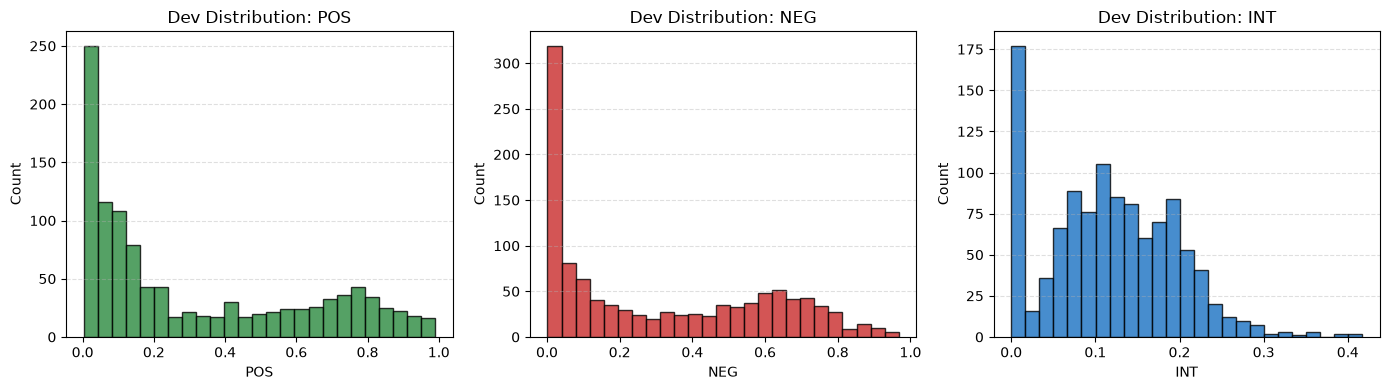

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col, color in zip(
    axes,
    ["POS", "NEG", "INT"],
    ["#2b8a3e", "#c92a2a", "#1971c2"],
):
    ax.hist(dev_df[col], bins=25, color=color, edgecolor="black", alpha=0.8)
    ax.set_title(f"Dev Distribution: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
    # Pick the numeric target column available in sst_dev_features.parquet
    candidate_targets = ["score", "fine_label", "label", "sentiment_score", "y"]
    target_col = next((c for c in candidate_targets if c in dev_df.columns), None)

    if target_col is None:
        numeric_cols = [c for c in dev_df.select_dtypes(include=[np.number]).columns
                        if c not in {"POS", "NEG", "INT", "clue_a", "clue_b", "clue_c", "clue_d",
                                    "p_neg", "p_neu", "p_pos", "vpos", "vneg", "compound"}]
        target_col = numeric_cols[0]

    print(f"Using target column: '{target_col}' (n={len(dev_df)})\n")

    rows = []
    for feat in ["POS", "NEG", "INT"]:
        pearson_r = dev_df[feat].corr(dev_df[target_col], method="pearson")
        spearman_rho = dev_df[feat].corr(dev_df[target_col], method="spearman")
        rows.append({
            "feature": feat,
            "pearson_r": round(float(pearson_r), 4),
            "spearman_rho": round(float(spearman_rho), 4),
        })

    corr_df = pd.DataFrame(rows)
    display(corr_df)

Using target column: 'score' (n=1101)



,feature,pearson_r,spearman_rho
0,POS,0.6851,0.6653
1,NEG,-0.6732,-0.7059
2,INT,0.1368,0.1559
